<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Notebooks/11-SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Máquinas de soporte vectorial
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; Periodo 2026-2
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

Este notebook está diseñado como una guía introductoria para implementar Máquinas de soporte vectorial (SVM) en Python.



Los paquetes necesarios son:

In [21]:
import pandas as pd  # Manejo de datos
import matplotlib.pyplot as plt  # Visualización

from sklearn.preprocessing import StandardScaler  # Estandarización de datos
from sklearn.datasets import make_blobs, make_circles, make_moons # Creación de datos
from sklearn.model_selection import train_test_split # División de datos
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # Métrica de evaluación

from sklearn.svm import SVR
from sklearn.metrics import r2_score

---
## <font color='264CC7'> Ejemplo </font>

En el siguiente código, se muestra un ejemplo de cómo implementar Máquinas de soporte vectorial (SVM) en Python. Primero carguemos los datos y analicemos su estructura.

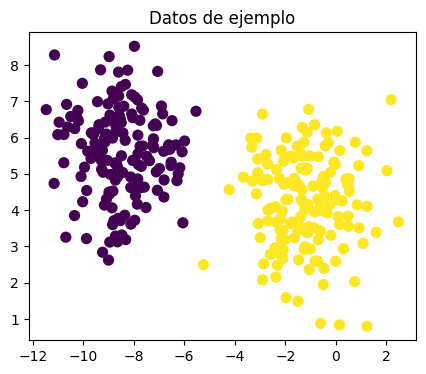

In [22]:
# Generamos los datos
X, y = make_blobs(n_samples=300, centers=2, cluster_std=1.3, random_state=7)

# Visualizar los datos
plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], s=50, c=y)
plt.title('Datos de ejemplo')
plt.show()


Reservamos prueba y separamos entrenamiento y validación; las comparaciones de este ejemplo utilizan validación, sin consultar prueba. Los datos sintéticos tienen escalas comparables.


In [23]:
# Reservar prueba; usar validación para las comparaciones del ejemplo
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval
)

Entrenamos el modelo:

In [24]:
# Crear y entrenar el modelo SVM
modelo = SVC(kernel='linear')
modelo.fit(X_train, y_train)

SVC(kernel='linear')

Revisamos la exactitud del modelo (accuracy):

In [25]:
# Realizar predicciones y evaluar el modelo
y_pred = modelo.predict(X_val)

# Exactitud del modelo (accuracy) con dos decimales
accuracy = round(accuracy_score(y_val, y_pred), 2)
print("Exactitud del modelo (accuracy):", accuracy)

# Matriz de confusión
cm = confusion_matrix(y_val, y_pred)
print("Matriz de confusión:")
print(cm)

# Reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(y_val, y_pred))

Exactitud del modelo (accuracy): 1.0
Matriz de confusión:
[[30  0]
 [ 0 30]]
Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        30

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



Podemos visualizar las regiones de decisión del modelo:

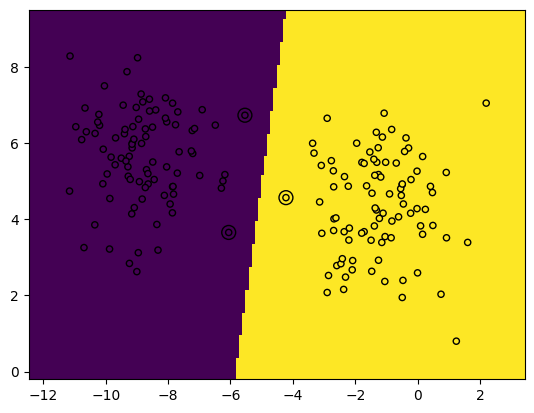

In [26]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np

# Datos para el fondo
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, .1),
                         np.arange(y_min, y_max, 0.1))
Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()])

# Crear el fondo
Z = Z.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx, yy, Z)

# Puntos de entrenamiento
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train,
                edgecolor='k', s=20)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())

# Soporte de los vectores
sv = modelo.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], s=100, facecolors='none', edgecolors='k')

plt.show()

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Aumenta la dispersión de los datos de entrenamiento y observa cómo cambia la exactitud del modelo.
</div>
</br>
<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Aumenta el número de centros de los datos de entrenamiento y observa cómo cambia la visualización de las regiones de decisión.
</div>

---
## <font color='264CC7'> Kernel </font>

Revisemos datos que no son linealmente separables:

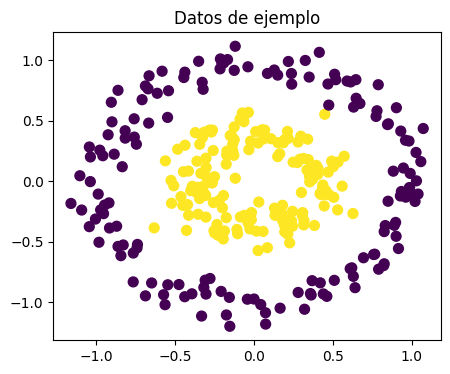

In [27]:
# Generamos los datos
X, y = make_circles(n_samples=300, factor=.4, noise=0.1, random_state=7)

# Visualizar los datos
plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], s=50, c=y)
plt.title('Datos de ejemplo')
plt.show()

Realicemos el mismo procedimiento que antes:

In [28]:
# Reservar prueba; usar validación para las comparaciones del ejemplo
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval
)

# Crear y entrenar el modelo SVM
modelo = SVC(kernel='linear')
modelo.fit(X_train, y_train)

# Realizar predicciones y evaluar el modelo
y_pred = modelo.predict(X_val)

# Exactitud del modelo (accuracy) con dos decimales
accuracy = round(accuracy_score(y_val, y_pred), 2)
print("Exactitud del modelo (accuracy):", accuracy)

# Matriz de confusión
cm = confusion_matrix(y_val, y_pred)
print("Matriz de confusión:")
print(cm)

# Reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(y_val, y_pred))


Exactitud del modelo (accuracy): 0.57
Matriz de confusión:
[[12 18]
 [ 8 22]]
Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.60      0.40      0.48        30
           1       0.55      0.73      0.63        30

    accuracy                           0.57        60
   macro avg       0.57      0.57      0.55        60
weighted avg       0.57      0.57      0.55        60



Visualicemos las regiones de decisión:

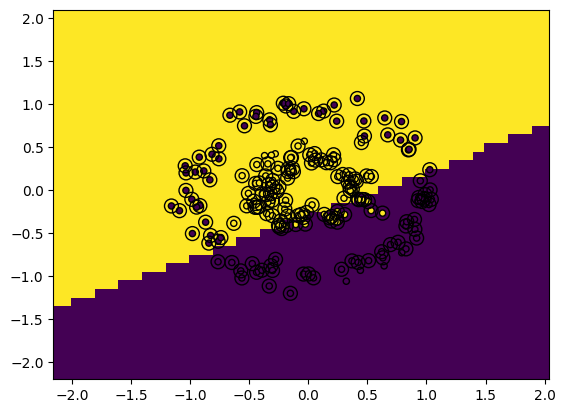

In [29]:
# Datos para el fondo
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, .1),
                         np.arange(y_min, y_max, 0.1))
Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()])

# Crear el fondo
Z = Z.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx, yy, Z)

# Puntos de entrenamiento
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train,
                edgecolor='k', s=20)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())

# Soporte de los vectores
sv = modelo.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], s=100, facecolors='none', edgecolors='k')

plt.show()

Apliquemos un kernel rbf:

In [30]:
# Reservar prueba; usar validación para las comparaciones del ejemplo
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval
)

# Crear y entrenar el modelo SVM
modelo = SVC(kernel='rbf')
modelo.fit(X_train, y_train)

# Realizar predicciones y evaluar el modelo
y_pred = modelo.predict(X_val)

# Exactitud del modelo (accuracy) con dos decimales
accuracy = round(accuracy_score(y_val, y_pred), 2)
print("Exactitud del modelo (accuracy):", accuracy)

# Matriz de confusión
cm = confusion_matrix(y_val, y_pred)
print("Matriz de confusión:")
print(cm)

# Reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(y_val, y_pred))

Exactitud del modelo (accuracy): 1.0
Matriz de confusión:
[[30  0]
 [ 0 30]]
Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        30

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



Visualicemos las regiones de decisión:

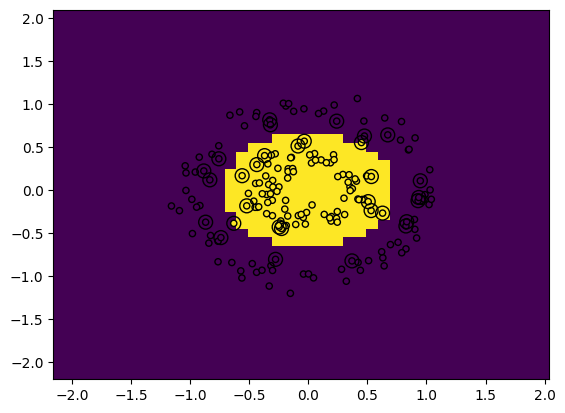

In [31]:
# Datos para el fondo
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, .1),
                         np.arange(y_min, y_max, 0.1))
Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()])

# Crear el fondo
Z = Z.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx, yy, Z)

# Puntos de entrenamiento
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train,
                edgecolor='k', s=20)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())

# Soporte de los vectores
sv = modelo.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], s=100, facecolors='none', edgecolors='k')

plt.show()

<div style="background-color: #edf1f8; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicios:</strong><br>
Utiliza las particiones ya definidas; si generas otros datos, reserva prueba y separa entrenamiento y validación con semillas registradas y estratificación.
<ul>
<li>Compara kernels polinómicos de grados 2 y 3 mediante exactitud de validación y regiones de decisión.</li>
<li>Genera datos con <code>make_moons</code> y repite la comparación manteniendo las particiones fijas.</li>
<li>Para datos no linealmente separables, grafica la exactitud de entrenamiento y validación frente al grado del kernel.</li>
</ul>
Selecciona sin consultar prueba y evalúa una sola vez al finalizar; las comparaciones lineal/RBF anteriores utilizan validación e ilustran fronteras; no constituyen una evaluación final en prueba.
</div>

---
## <font color='264CC7'> Ejemplo práctico </font>


### <font color='264CC7'> Preprocesamiento de datos </font>

Primero leamos los datos y seleccionemos las columnas que utilizaremos:

In [32]:
# Leer los datos
data = pd.read_csv('https://raw.githubusercontent.com/andres-merino/AprendizajeAutomaticoInicial-05-N0105/refs/heads/main/2-Notebooks/datos/Pokemon.csv')
# Tomo las columnas de interés
numeric_cols = ['Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def', 'HP']
class_col = ['Stage']
data = data[['Name', *numeric_cols, *class_col]]
# Muestro los primeros registros
display(data.head())

,Name,Attack,Defense,Speed,Sp. Atk,Sp. Def,HP,Stage
0,Bulbasaur,49,49,45,65,65,45,2
1,Ivysaur,62,63,60,80,80,60,1
2,Venusaur,82,83,80,100,100,80,0
3,Charmander,52,43,65,60,50,39,2
4,Charmeleon,64,58,80,80,65,58,1


Revisemos los datos:

In [33]:
data.describe()

,Attack,Defense,Speed,Sp. Atk,Sp. Def,HP,Stage
count,151.000000,151.000000,151.000000,151.000000,151.000000,151.000000,151.000000
mean,72.549669,68.225166,68.933775,67.139073,66.019868,64.211921,0.569536
std,26.596162,26.916704,26.746880,28.534199,24.197926,28.590117,0.678331
min,5.000000,5.000000,15.000000,15.000000,20.000000,10.000000,0.000000
25%,51.000000,50.000000,46.500000,45.000000,49.000000,45.000000,0.000000
50%,70.000000,65.000000,70.000000,65.000000,65.000000,60.000000,0.000000
75%,90.000000,84.000000,90.000000,87.500000,80.000000,80.000000,1.000000
max,134.000000,180.000000,140.000000,154.000000,125.000000,250.000000,2.000000


Reservemos prueba y validación antes de escalar; el escalador se ajusta solo con entrenamiento.


In [34]:
# Reservar prueba antes de ajustar cualquier transformación
X = data[numeric_cols]
y = data['Stage']
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval
)

# Ajustar el escalado solo con entrenamiento; transformar validación
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)


### <font color='264CC7'> Selección del kernel y ajuste de C y gamma </font>


Comparamos kernels y valores de C en la misma validación; para RBF también variamos gamma. C penaliza las violaciones del margen y gamma controla el alcance de la influencia de cada punto. La exactitud (accuracy) cuenta aciertos totales y se distingue de precision por clase. No utilizamos prueba para elegir.


In [35]:
# Búsqueda pequeña y explícita sobre la misma validación
configurations = [
    {'kernel': kernel, 'C': c}
    for kernel in ['linear', 'poly', 'sigmoid'] for c in [0.1, 1, 10]
] + [
    {'kernel': 'rbf', 'C': c, 'gamma': gamma}
    for c in [0.1, 1, 10] for gamma in [0.01, 0.1, 1]
]
results = []
for params in configurations:
    modelo = SVR(**params)
    modelo.fit(X_train_scaled, y_train)
    results.append({
        'params': params,
        'accuracy_train': accuracy_score(y_train, modelo.predict(X_train_scaled)),
        'accuracy_val': accuracy_score(y_val, modelo.predict(X_val_scaled))
    })

# En caso de empate se conserva la primera configuración evaluada
best_result = max(results, key=lambda row: row['accuracy_val'])
best_params = best_result['params'].copy()
display(pd.DataFrame(results))
print("Configuración seleccionada en validación:", best_params)
plt.figure(figsize=(10, 3))
plt.plot(range(len(results)), [r['accuracy_val'] for r in results], label="validación")
plt.plot(range(len(results)), [r['accuracy_train'] for r in results], label="entrenamiento")
plt.xticks(range(len(results)), [str(r['params']) for r in results], rotation=90)
plt.ylabel("Exactitud (accuracy)")
plt.legend()
plt.show()


ValueError: Classification metrics can't handle a mix of multiclass and continuous targets

La configuración se elige por validación, sin presuponer que RBF sea siempre el mejor. El kernel sigmoide se incluye como comparación exploratoria: no garantiza una matriz de Gram semidefinida positiva para cualquier combinación de datos y parámetros. Las salidas conservadas corresponden a la versión anterior y deben actualizarse al ejecutar el notebook.


### <font color='264CC7'> Modelo SVM </font>

Generemos el modelo con el kernel seleccionado:

In [ ]:
# Reajustar con entrenamiento y validación tras fijar la configuración
scaler_final = StandardScaler()
X_trainval_scaled = scaler_final.fit_transform(X_trainval)
X_test_scaled = scaler_final.transform(X_test)
modelo = SVC(**best_params)
modelo.fit(X_trainval_scaled, y_trainval)

# Evaluación final: no usar estos resultados para volver a ajustar
y_pred = modelo.predict(X_test_scaled)
print("Exactitud final (accuracy):", round(accuracy_score(y_test, y_pred), 2))
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))
print("Reporte de clasificación (precision, recall y F1 por clase):")
print(classification_report(y_test, y_pred, zero_division=0))
